# Improve KumoRelational regression accuracy

KumoRelational, a relational foundation model (RFM), predicts from labeled in-context examples. This notebook demonstrates three levers for a skewed target plus sampling settings, and measures the lift of each, using a banking example: how much will each account spend in the next 30 days?

| Strategy | Targets | What changes |
| --- | --- | --- |
| 1. Compose the context | Skewed target | Context size, stratification by target band, and oversampling of the high-value tail. |
| 2. Ensemble contexts | Skewed target | Average the quantile predictions of several context draws. |
| 3. Tune sampling | Any dataset | Recent entities, most recent neighbors, neighbor count. |
| 4. Choose the output quantile | Skewed target | Pick the reported quantile on validation data for each configuration. |

Sampling does not address the skew and can help any dataset as much, so the lift summary reports it separately.

Runs locally with Python 3.12+ and [direct KumoRelational](https://nvidia.github.io/structured-data-models/api/generated/sdm.models.KumoRelational.html). A GPU is recommended. Data is synthetic; metrics are **demonstration only**.

## Install and configure

Sampling runs on CPU even when the model uses a GPU, so it always needs a [pyg-lib wheel](https://pytorch-geometric.readthedocs.io/en/latest/install/installation.html) matching your PyTorch version; the schema diagram needs [Graphviz](https://graphviz.org/download/). See [installation](https://nvidia.github.io/structured-data-models/install.html).

In [1]:
%pip install structured-data-models pandas pyarrow scikit-learn scipy matplotlib graphviz

## Set the parameters

Accounts are split by observation date into a context pool, a validation window for choosing settings and quantiles, and a test window for reporting. `TOP_SHARE` defines the high-value tail used for tail metrics and stratification.

In [2]:
SEED = 7
N_ACCOUNTS = 80_000
START = "2026-01-01"
HISTORY_DAYS = 90
HORIZON_DAYS = 30
VALIDATION_START_DAY = 250
TEST_START_DAY = 310

BASELINE_CONTEXT_SIZE = 5_000
LARGE_CONTEXT_SIZE = 10_000
ROWS_PER_BAND = 2_500
TOP_REPEAT = 3
TOP_SHARE = 0.02
NUM_ESTIMATORS = 5
RECENT_CONTEXT_DAYS = 90
FIRST_HOP_NEIGHBORS = 8
SECOND_HOP_NEIGHBORS = 4
NEIGHBOR_OPTIONS = [16]

QUANTILES = [round(q, 2) for q in [0.05 * i for i in range(1, 20)]]
UNDER_PREDICTION_COST = 3.0
OUTPUT_PARENT = None
CLEANUP = False

Import the libraries and create an output directory for this run.

In [3]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sdm
import torch
from IPython.display import display
from scipy.stats import spearmanr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
rng = np.random.default_rng(SEED)
workspace = tempfile.TemporaryDirectory(prefix="spend-context-tuning-", dir=OUTPUT_PARENT, delete=False)
run_dir = Path(workspace.name)
print("Device:", device, "| Results:", run_dir)

## Generate synthetic example data

Run the next cell to create five tables: customers, accounts, transactions, merchants and devices. You can skim it; the workflow starts at **Build the relational data**.

About a third of accounts go quiet before their observation date and spend nothing in the next 30 days. About 1% are high spenders who shop at premium merchants. Future spend tracks each account's activity in its last 10 days, and high spenders move from in-store to online premium merchants in late May. Accounts carry an open date, so the sampler can exclude accounts opened after each observation date.

In [4]:
N_CUSTOMERS = int(N_ACCOUNTS * 0.75)
N_MERCHANTS = 2_000
DRIFT_DAY = 150

merchants = pd.DataFrame({
    "merchant_id": np.arange(N_MERCHANTS),
    "avg_ticket": rng.lognormal(3.6, 0.7, N_MERCHANTS).round(2),
    "is_online": (rng.random(N_MERCHANTS) < 0.4).astype(float),
})
premium = (merchants.avg_ticket > merchants.avg_ticket.quantile(0.9)).to_numpy()
premium_merchants = {
    "early": merchants.merchant_id[premium & (merchants.is_online == 0)].to_numpy(),
    "late": merchants.merchant_id[premium & (merchants.is_online == 1)].to_numpy(),
}
everyday_merchants = merchants.merchant_id[~premium].to_numpy()

customers = pd.DataFrame({
    "customer_id": np.arange(N_CUSTOMERS),
    "customer_age_years": rng.integers(18, 85, N_CUSTOMERS).astype(float),
    "income_band": rng.integers(1, 6, N_CUSTOMERS).astype(float),
})
devices = pd.DataFrame({
    "device_id": np.arange(N_CUSTOMERS),
    "is_mobile": (rng.random(N_CUSTOMERS) < 0.7).astype(float),
})


def simulate_accounts(account_ids, anchors):
    n = len(account_ids)
    owner = rng.integers(0, N_CUSTOMERS, n)
    income = customers.income_band.to_numpy()[owner]
    segment = rng.choice(["dormant", "regular", "high"], n, p=[0.35, 0.64, 0.01])
    rate = rng.lognormal(-1.3, 0.5, n)
    amount_scale = rng.lognormal(3.3, 0.4, n) * (0.7 + 0.15 * income) * np.where(segment == "high", 8.0, 1.0)
    premium_share = np.where(segment == "high", 0.5, 0.05)
    momentum = np.where(segment == "dormant", 0.0, rng.lognormal(0, 0.6, n))
    quiet_days = np.where(segment == "dormant", rng.uniform(12, 30, n), 10.0)

    windows = [(rng.poisson(rate * (HISTORY_DAYS - 10)), np.full(n, float(HISTORY_DAYS)), quiet_days),
               (rng.poisson(rate * momentum * 10), np.full(n, 10.0), np.zeros(n))]
    parts = []
    for counts, oldest, newest in windows:
        i = np.repeat(np.arange(n), counts)
        timestamp = anchors.values[i] - pd.to_timedelta(rng.uniform(newest[i], oldest[i]), unit="D")
        after_switch = (timestamp - pd.Timestamp(START)).days.to_numpy() >= DRIFT_DAY
        use_premium = rng.random(len(i)) < premium_share[i]
        premium_pick = np.where(after_switch, rng.choice(premium_merchants["late"], len(i)), rng.choice(premium_merchants["early"], len(i)))
        merchant = np.where(use_premium, premium_pick, rng.choice(everyday_merchants, len(i)))
        parts.append(pd.DataFrame({
            "account_id": account_ids[i], "merchant_id": merchant, "device_id": owner[i], "timestamp": timestamp,
            "amount": (amount_scale[i] * rng.lognormal(0, 0.6, len(i)) * np.where(use_premium, 3.0, 1.0)).round(2),
            "hour_of_day": rng.normal(14, 4, len(i)).clip(0, 23).round(),
        }))
    transaction_frame = pd.concat(parts, ignore_index=True).sort_values("timestamp", ignore_index=True)
    transaction_frame["timestamp"] = transaction_frame.timestamp.dt.floor("s")

    future_spend = rng.poisson(rate * momentum * 30) * amount_scale * (1 + 2 * premium_share) * rng.lognormal(0, 0.3, n)
    account_frame = pd.DataFrame({
        "account_id": account_ids, "customer_id": owner,
        "opened_at": anchors - pd.to_timedelta(rng.gamma(3.0, 300, n).round() + HISTORY_DAYS, unit="D"),
        "credit_limit": (rng.lognormal(8.0, 0.5, n) * (0.6 + 0.2 * income) * np.where(segment == "high", 2.0, 1.0)).round(-2),
    })
    label_frame = pd.DataFrame({"account_id": account_ids, "timestamp": anchors, "spend_30d": future_spend.round(2)})
    return account_frame, transaction_frame, label_frame


history_anchors = pd.Timestamp(START) + pd.to_timedelta(rng.integers(60, 365, N_ACCOUNTS), unit="D")
accounts, transactions, labels = simulate_accounts(np.arange(N_ACCOUNTS), history_anchors)
transactions.insert(0, "transaction_id", np.arange(len(transactions)))

display(pd.Series({"customers": len(customers), "accounts": len(accounts), "transactions": len(transactions),
                   "merchants": len(merchants), "devices": len(devices)}, name="rows").to_frame())
display(labels.spend_30d.describe(percentiles=[0.35, 0.5, 0.9, 0.99]).round(1).to_frame().T)

,rows
customers,60000
accounts,80000
transactions,2165327
merchants,2000
devices,60000


,count,mean,std,min,35%,50%,90%,99%,max
spend_30d,80000.0,347.3,1213.0,0.0,0.0,124.9,789.6,3120.9,108651.6


## Build the relational data

Declare column types and foreign keys. KumoRelational uses numerical and datetime features. The sampler only uses transactions and accounts dated before each observation date, so another account of the same customer opened later is excluded; customer, merchant and device attributes are static. See [RelationalData](https://nvidia.github.io/structured-data-models/api/generated/sdm.relational.RelationalData.html).

In [5]:
STYPES = {
    "customers": {"customer_id": "id", "customer_age_years": "numerical", "income_band": "numerical"},
    "accounts": {"account_id": "id", "customer_id": "id", "opened_at": "datetime", "credit_limit": "numerical"},
    "merchants": {"merchant_id": "id", "avg_ticket": "numerical", "is_online": "numerical"},
    "devices": {"device_id": "id", "is_mobile": "numerical"},
    "transactions": {
        "transaction_id": "id", "account_id": "id", "merchant_id": "id", "device_id": "id",
        "timestamp": "datetime", "amount": "numerical", "hour_of_day": "numerical",
    },
}
RELATIONSHIPS = [
    {"left_table": "accounts", "left_column": "customer_id", "right_table": "customers", "right_column": "customer_id"},
    {"left_table": "transactions", "left_column": "account_id", "right_table": "accounts", "right_column": "account_id"},
    {"left_table": "transactions", "left_column": "merchant_id", "right_table": "merchants", "right_column": "merchant_id"},
    {"left_table": "transactions", "left_column": "device_id", "right_table": "devices", "right_column": "device_id"},
]
TASK_LINK = {"task_column": "account_id", "table": "accounts", "table_column": "account_id"}

frames = {"customers": customers, "accounts": accounts, "merchants": merchants, "devices": devices, "transactions": transactions}
data = sdm.RelationalData(
    tables={name: sdm.TableTensor.from_pandas(frame, stypes=STYPES[name]) for name, frame in frames.items()},
    relationships=RELATIONSHIPS,
)
sampler = data.sampler(time_columns={"transactions": "timestamp", "accounts": "opened_at"})
task_table = sdm.TableTensor.from_pandas(labels, stypes={"account_id": "id", "timestamp": "datetime", "spend_30d": "numerical"})

Merchant spend levels sit two hops from an account, through its transactions.

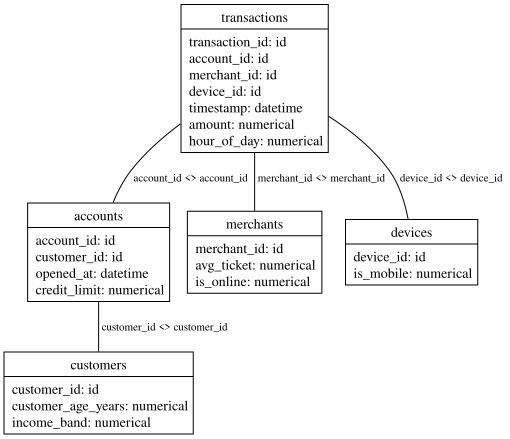

In [6]:
data.to_graphviz()

## Split accounts by time

Each label needs 30 days to mature, so each window ends 30 days before the next one starts: context pool before day 220, validation days 250 to 279, test from day 310. Settings are then fixed using only outcomes known before the windows they are applied to. Spend bands (zero, low, mid, top) come from the pool's distribution.

In [7]:
observation_day = (labels.timestamp - pd.Timestamp(START)).dt.days.to_numpy()
spend = labels.spend_30d.to_numpy()
pool_rows = np.flatnonzero(observation_day < VALIDATION_START_DAY - HORIZON_DAYS)
val_rows = np.flatnonzero((observation_day >= VALIDATION_START_DAY) & (observation_day < TEST_START_DAY - HORIZON_DAYS))
test_rows = np.flatnonzero(observation_day >= TEST_START_DAY)
y_val, y_test = spend[val_rows], spend[test_rows]

pool_spend = spend[pool_rows]
top_cut = np.quantile(pool_spend, 1 - TOP_SHARE)
band = np.digitize(spend, [1e-9, np.median(pool_spend[pool_spend > 0]), top_cut])
display(pd.DataFrame({
    "accounts": [len(pool_rows), len(val_rows), len(test_rows)],
    "zero_spend_share": [np.mean(spend[r] == 0) for r in (pool_rows, val_rows, test_rows)],
    "top_band_accounts": [np.sum(band[r] == 3) for r in (pool_rows, val_rows, test_rows)],
}, index=["context pool", "validation", "test"]).round(3))

,accounts,zero_spend_share,top_band_accounts
context pool,41927,0.359,839
validation,7902,0.364,179
test,14322,0.355,288


## Define the helpers

`score_contexts` fits the model on each context, scores the queries and averages each quantile across contexts; `score_validation` scores only validation accounts for tuning trials; one context is an ensemble of one. It keeps the `QUANTILES` grid from the model's 999 outputs. Sampling covers two hops: `num_neighbors` transactions per account, then each transaction's merchant and device, plus up to `SECOND_HOP_NEIGHBORS` accounts per customer. See [RelationalSampler](https://nvidia.github.io/structured-data-models/api/generated/sdm.relational.RelationalSampler.html).

Metrics: overall MAE, MAE on the top band, Spearman correlation, and top-band capture: the share of actual top-band accounts ranked in the predicted top k, where k is the number of top-band accounts. The top-band metrics are most telling when a few accounts drive most of the value.

In [8]:
model = sdm.models.KumoRelational(device=device)
evaluation_query = task_table[torch.as_tensor(np.concatenate([val_rows, test_rows]))].drop_columns("spend_30d")
QUANTILE_COLUMNS = [f"q{round(q * 1000):03d}" for q in QUANTILES]


def predict_grid(contexts, query, num_neighbors=FIRST_HOP_NEIGHBORS, temporal_strategy="uniform", batch_size=5_000):
    options = dict(task_link=TASK_LINK, num_neighbors=[num_neighbors, SECOND_HOP_NEIGHBORS],
                   task_time_column="timestamp", temporal_strategy=temporal_strategy)
    members = []
    for context_rows in contexts:
        torch.manual_seed(SEED)
        context, related = sampler(task_table[torch.as_tensor(context_rows)], **options).to(device)
        model.fit(x=context.drop_columns("spend_30d"), y=context["spend_30d"], related_tables=related)
        batches = []
        for query_batch in query.split(batch_size, -2):
            out = model.predict(*sampler(query_batch, **options).to(device))
            columns = list(out.columns[sdm.Stype.numerical])
            batches.append(out.numerical[:, [columns.index(c) for c in QUANTILE_COLUMNS]].float().cpu().numpy())
        members.append(np.concatenate(batches))
    return np.mean(members, axis=0)


def score_contexts(contexts, **options):
    grid = predict_grid(contexts, evaluation_query, **options)
    return grid[: len(val_rows)], grid[len(val_rows):]


def score_validation(contexts, **options):
    return predict_grid(contexts, evaluation_query[: len(val_rows)], **options)


def capture(y_true, prediction):
    in_band = y_true >= top_cut
    k = max(1, int(in_band.sum()))
    return in_band[np.argsort(-prediction)[:k]].sum() / k


def metrics(y_true, grid, quantile):
    prediction = grid[:, QUANTILES.index(quantile)]
    top = y_true >= top_cut
    return {
        "mae": np.abs(prediction - y_true).mean(),
        "top_band_mae": np.abs(prediction[top] - y_true[top]).mean(),
        "spearman": spearmanr(prediction, y_true).statistic,
        "top_band_capture": capture(y_true, prediction),
        "quantile": quantile,
    }


def best_quantile(y_true, grid, under_cost=1.0):
    errors = grid - y_true[:, None]
    loss = np.where(errors < 0, -under_cost * errors, errors).mean(axis=0)
    return QUANTILES[int(np.argmin(loss))]


def tuned_val_mae(val_grid):
    return metrics(y_val, val_grid, best_quantile(y_val, val_grid))["mae"]


stages = {}

## Score the baseline

Use a random context at the natural target distribution and report the median (q0.50).

In [9]:
baseline_context = rng.choice(pool_rows, BASELINE_CONTEXT_SIZE, replace=False)
stages["Baseline"] = score_contexts([baseline_context])
print(f"Top-band accounts in the baseline context: {np.sum(band[baseline_context] == 3)} of {BASELINE_CONTEXT_SIZE}")
display(pd.DataFrame({"Baseline, median": metrics(y_test, stages["Baseline"][1], 0.5)}).T.round(3))

Top-band accounts in the baseline context: 103 of 5000


,mae,top_band_mae,spearman,top_band_capture,quantile
"Baseline, median",253.665,2828.415,0.612,0.448,0.5


## Strategy 1: compose the context

Compare a larger random context, equal rows per spend band, every top-band account plus random fill, and the top band repeated `TOP_REPEAT` times. Each candidate is judged at its own validation-tuned quantile, since composition shifts the predicted distribution. This is most useful when the target is skewed, as a random context then holds few high-value examples.

In [10]:
def natural(rows, size):
    return rng.choice(rows, size, replace=False)


def stratified(rows):
    return np.concatenate([rng.choice(rows[band[rows] == b], min(ROWS_PER_BAND, np.sum(band[rows] == b)), replace=False) for b in range(4)])


def top_plus_natural(rows, repeat):
    top_rows = rows[band[rows] == 3]
    return np.concatenate([np.tile(top_rows, repeat), natural(rows[band[rows] < 3], LARGE_CONTEXT_SIZE - repeat * len(top_rows))])


context_designs = {
    f"Natural, {BASELINE_CONTEXT_SIZE:,} rows": lambda rows: natural(rows, BASELINE_CONTEXT_SIZE),
    f"Natural, {LARGE_CONTEXT_SIZE:,} rows": lambda rows: natural(rows, LARGE_CONTEXT_SIZE),
    "Stratified by band": stratified,
    "All top + natural": lambda rows: top_plus_natural(rows, 1),
    f"Top x{TOP_REPEAT} + natural": lambda rows: top_plus_natural(rows, TOP_REPEAT),
}
design_scores = {f"Natural, {BASELINE_CONTEXT_SIZE:,} rows": stages["Baseline"]}
for name, design in context_designs.items():
    if name not in design_scores:
        design_scores[name] = score_contexts([design(pool_rows)])

comparison = pd.DataFrame({
    name: {
        "tuned_quantile": best_quantile(y_val, val_grid),
        "validation_mae": tuned_val_mae(val_grid),
        "validation_mae_at_median": metrics(y_val, val_grid, 0.5)["mae"],
        "validation_top_band_mae": metrics(y_val, val_grid, best_quantile(y_val, val_grid))["top_band_mae"],
    }
    for name, (val_grid, _) in design_scores.items()
}).T
best_design = comparison.validation_mae.idxmin()
stages["+ Context composition"] = design_scores[best_design]
display(comparison.round(3))
print("Selected context design:", best_design)

,tuned_quantile,validation_mae,validation_mae_at_median,validation_top_band_mae
"Natural, 5,000 rows",0.40,263.107,276.052,3894.176
"Natural, 10,000 rows",0.45,265.194,266.303,3902.356
Stratified by band,0.30,268.686,313.568,3777.483
All top + natural,0.35,268.103,297.511,3826.499
Top x3 + natural,0.25,285.006,383.788,3809.389


Selected context design: Natural, 5,000 rows


Oversampling the tail raises the whole predicted distribution, so it needs a lower quantile, and its error at the median grows. Whether it helps after re-tuning depends on how well features already identify the tail. If the baseline design wins, this stage matches the tuned baseline.

## Strategy 2: ensemble contexts

Draw `NUM_ESTIMATORS` contexts with the selected design and average each quantile across members. See [ensembling](https://nvidia.github.io/structured-data-models/icl.html).

In [11]:
design = context_designs[best_design]
ensemble_contexts = [design(pool_rows) for _ in range(NUM_ESTIMATORS)]
member_scores = [score_contexts([context]) for context in ensemble_contexts]
stages["+ Context ensemble"] = tuple(np.mean([member[i] for member in member_scores], axis=0) for i in range(2))
print("Validation MAE per member:", np.round([tuned_val_mae(val_grid) for val_grid, _ in member_scores], 1))
print(f"Validation MAE of the ensemble: {tuned_val_mae(stages['+ Context ensemble'][0]):.1f}")

Validation MAE per member: [268.1 268.4 266.4 263.  259.7]
Validation MAE of the ensemble: 251.3


## Strategy 3: tune sampling

These settings change how neighbors are sampled, not how the target distribution is represented, so they apply to any dataset. Test each change on the first ensemble member's context rows, so only the sampling setting changes, and keep it only if validation MAE, at its tuned quantile, improves:

* **Recent accounts:** apply the selected design to the pool's last 90 days. This can change the context size too.
* **Most recent transactions:** `temporal_strategy="last"` instead of a uniform sample.
* **More neighbors:** more first-hop transactions per account.

In [12]:
recent_rows = pool_rows[observation_day[pool_rows] >= VALIDATION_START_DAY - RECENT_CONTEXT_DAYS]


trial_contexts = {False: ensemble_contexts[0], True: design(recent_rows)}
trials = []


def record(change, use_recent, num_neighbors, temporal_strategy, val_grid):
    trials.append({"change": change, "context_rows": len(trial_contexts[use_recent]), "num_neighbors": num_neighbors,
                   "temporal_strategy": temporal_strategy, "validation_mae": tuned_val_mae(val_grid)})
    return trials[-1]["validation_mae"]


def try_settings(change, use_recent, num_neighbors, temporal_strategy):
    val_grid = score_validation([trial_contexts[use_recent]], num_neighbors=num_neighbors, temporal_strategy=temporal_strategy)
    return record(change, use_recent, num_neighbors, temporal_strategy, val_grid)


default_settings = {"use_recent": False, "num_neighbors": FIRST_HOP_NEIGHBORS, "temporal_strategy": "uniform"}
settings = dict(default_settings)
best_mae = record("Current settings", **settings, val_grid=member_scores[0][0])
for change, update in [("Recent accounts", {"use_recent": True}), ("Most recent transactions", {"temporal_strategy": "last"})] + [
    (f"{n} neighbors", {"num_neighbors": n}) for n in NEIGHBOR_OPTIONS
]:
    trial_mae = try_settings(change, **{**settings, **update})
    if trial_mae < best_mae:
        settings, best_mae = {**settings, **update}, trial_mae

display(pd.DataFrame(trials).round(3))
print("Selected sampling settings:", settings)

,change,context_rows,num_neighbors,temporal_strategy,validation_mae
0,Current settings,5000,8,uniform,268.115
1,Recent accounts,5000,8,uniform,270.079
2,Most recent transactions,5000,8,last,194.881
3,16 neighbors,5000,16,last,193.014


Selected sampling settings: {'use_recent': False, 'num_neighbors': 16, 'temporal_strategy': 'last'}


Score the ensemble with the selected settings. It keeps the same members unless the recent pool was selected, which the stage name then states.

In [13]:
sampling_options = {"num_neighbors": settings["num_neighbors"], "temporal_strategy": settings["temporal_strategy"]}
if settings["use_recent"]:
    final_stage = "+ Sampling settings (recent pool)"
    final_contexts = [trial_contexts[True]] + [design(recent_rows) for _ in range(NUM_ESTIMATORS - 1)]
else:
    final_stage = "+ Sampling settings"
    final_contexts = ensemble_contexts
if settings == default_settings:
    stages[final_stage] = stages["+ Context ensemble"]
else:
    stages[final_stage] = score_contexts(final_contexts, **sampling_options)

## Strategy 4: choose the output quantile per configuration

Pick the quantile with the lowest validation MAE for every stage. Re-pick whenever the context or sampling changes. The choice matters more for skewed targets, where the median and the best quantile can sit far apart.

In [14]:
tuned_quantiles = {name: best_quantile(y_val, val_grid) for name, (val_grid, _) in stages.items()}
display(pd.Series(tuned_quantiles, name="mae_quantile").to_frame())

,mae_quantile
Baseline,0.40
+ Context composition,0.40
+ Context ensemble,0.45
+ Sampling settings,0.50


When under-forecasting costs more than over-forecasting, for example in liquidity or limit planning, choose the quantile that minimizes that asymmetric cost instead. Compare both on the final configuration.

In [15]:
final_val, final_test = stages[final_stage]
cost_quantile = best_quantile(y_val, final_val, under_cost=UNDER_PREDICTION_COST)
operating_points = {}
for name, quantile in [("Min MAE", tuned_quantiles[final_stage]), (f"Under-forecast cost x{UNDER_PREDICTION_COST:g}", cost_quantile)]:
    prediction = final_test[:, QUANTILES.index(quantile)]
    errors = prediction - y_test
    operating_points[name] = {
        **metrics(y_test, final_test, quantile),
        "asymmetric_cost": np.where(errors < 0, -UNDER_PREDICTION_COST * errors, errors).mean(),
        "under_forecast_share": np.mean(errors < 0),
    }
display(pd.DataFrame(operating_points).T.round(3))

,mae,top_band_mae,spearman,top_band_capture,quantile,asymmetric_cost,under_forecast_share
Min MAE,178.940,2116.339,0.838,0.632,0.50,427.969,0.468
Under-forecast cost x3,218.072,2442.327,0.825,0.625,0.65,366.190,0.261


## Compare the lift

Each row adds one strategy to the row above and, after the first row, reports its own tuned quantile. `mae_change` is the change from the row above. The summary reports the skew strategies and sampling separately. All rows use the same test accounts, and the table is saved to the run directory. **Demonstration only.**

In [16]:
lift_rows = {"Baseline, median": metrics(y_test, stages["Baseline"][1], 0.5)}
for name, (_, test_grid) in stages.items():
    lift_rows["Baseline, tuned quantile" if name == "Baseline" else name] = metrics(y_test, test_grid, tuned_quantiles[name])
summary = pd.DataFrame(lift_rows).T
summary["mae_change"] = summary.mae.diff()
summary.to_csv(run_dir / "lift_summary.csv")
display(summary.round(3))
first, skew, last = summary.iloc[0], summary.loc["+ Context ensemble"], summary.iloc[-1]
for label, start, end in [("Skew strategies 1, 2 and 4", first, skew), ("Sampling, strategy 3", skew, last)]:
    print(f"{label}: MAE {start.mae:.1f} -> {end.mae:.1f}; top-band MAE {start.top_band_mae:.1f} -> {end.top_band_mae:.1f}; "
          f"Spearman {start.spearman:.3f} -> {end.spearman:.3f}")

,mae,top_band_mae,spearman,top_band_capture,quantile,mae_change
"Baseline, median",253.665,2828.415,0.612,0.448,0.50,NaN
"Baseline, tuned quantile",246.187,3017.133,0.627,0.444,0.40,-7.477
+ Context composition,246.187,3017.133,0.627,0.444,0.40,0.000
+ Context ensemble,236.840,2949.087,0.748,0.476,0.45,-9.348
+ Sampling settings,178.940,2116.339,0.838,0.632,0.50,-57.899


Skew strategies 1, 2 and 4: MAE 253.7 -> 236.8; top-band MAE 2828.4 -> 2949.1; Spearman 0.612 -> 0.748
Sampling, strategy 3: MAE 236.8 -> 178.9; top-band MAE 2949.1 -> 2116.3; Spearman 0.748 -> 0.838


Plot the headline metrics by stage.

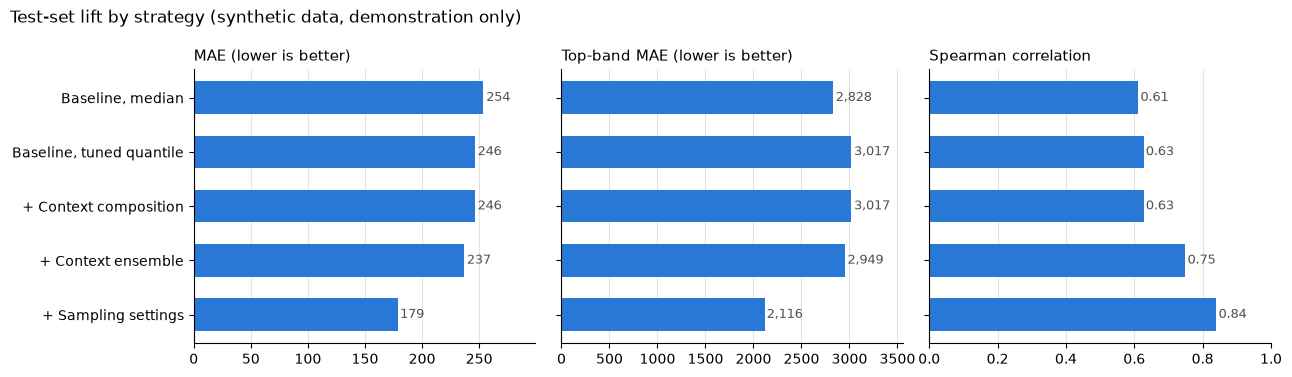

In [17]:
panels = [("mae", "MAE (lower is better)"), ("top_band_mae", "Top-band MAE (lower is better)"), ("spearman", "Spearman correlation")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for axis, (column, title) in zip(axes, panels):
    values = summary[column].to_numpy()[::-1]
    axis.barh(summary.index[::-1], values, color="#2a78d6", height=0.6)
    for position, value in enumerate(values):
        axis.text(value * 1.01, position, f"{value:,.2f}" if column == "spearman" else f"{value:,.0f}", va="center", fontsize=9, color="#52514e")
    axis.set_xlim(0, max(values) * 1.18 if column != "spearman" else 1)
    axis.set_title(title, loc="left", fontsize=11)
    axis.spines[["top", "right"]].set_visible(False)
    axis.grid(axis="x", color="#e4e3df", linewidth=0.8)
    axis.set_axisbelow(True)
fig.suptitle("Test-set lift by strategy (synthetic data, demonstration only)", x=0.01, ha="left", fontsize=12)
fig.tight_layout()
plt.show()

## Clean up

Set `CLEANUP = True` to delete this run's directory.

In [18]:
if CLEANUP:
    workspace.cleanup()
print("Removed this run's files." if CLEANUP else f"Results retained in {run_dir}.")